# EDA bước chung: dự báo gián đoạn chuyến bay

Dữ liệu: `data/02-preprocessed/flights.parquet` (tạo bởi `python -m entrypoint.prepare_data`), 13 tháng 12/2024 đến 12/2025.

**Phạm vi nhãn trong notebook này**
- Biểu đồ theo **tháng** và **số chuyến theo ngày** dùng toàn bộ 13 tháng (để thấy khác biệt mùa giữa train, val, test). Đây chỉ là mô tả, không dùng để chọn gì.
- Mọi phân tích còn lại (thứ, giờ, hãng, sân bay, mức tập trung, phân phối `ArrDelay`) **chỉ dùng train**, vì phạm vi sân bay sẽ được chốt dựa trên chúng.
- Tỉ lệ tính trên các chuyến có nhãn xác định (`label_status != undetermined`). Ba thành phần hủy / chuyển hướng / trễ ≥ 60 không giao nhau nên cộng lại đúng bằng tỉ lệ y=1.
- Cột dẫn xuất (giờ khởi hành, tháng dạng chuỗi...) chỉ tạo trong notebook để vẽ, không ghi vào file đầu vào mô hình.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.pipelines.utils import load_config, get_path, peak_rss_mb, ram_status

cfg = load_config()
FIG_DIR = get_path(cfg["eda"]["figures_dir"])
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Bảng màu tham chiếu (đã chạy validator: 3 slot đầu pass all-pairs)
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COMPONENTS = [("is_cancelled", "Hủy", "#2a78d6"),
              ("is_diverted", "Chuyển hướng", "#eb6834"),
              ("is_delay60", "Trễ ≥ 60 phút", "#1baf7a")]
COUNT_COLOR = "#9c9a92"  # số chuyến: màu trung tính, không trùng màu thành phần

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

def savefig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Đã lưu {path.relative_to(ROOT)}")

def rate_table(d, by):
    # Tỉ lệ y=1 và từng thành phần (trên chuyến có nhãn xác định) theo nhóm
    det = d[d["label_status"] != "undetermined"]
    t = det.groupby(by, observed=True).agg(
        n=("y", "size"), y1=("y", "mean"),
        is_cancelled=("is_cancelled", "mean"), is_diverted=("is_diverted", "mean"),
        is_delay60=("is_delay60", "mean"))
    t["y1"] = t["y1"].astype(float)
    return t

def fmt_rates(t):
    out = t.copy()
    for c in ["y1", "is_cancelled", "is_diverted", "is_delay60"]:
        out[c] = (out[c] * 100).round(2)
    return out.rename(columns={"n": "số chuyến", "y1": "y=1 %", "is_cancelled": "hủy %",
                               "is_diverted": "chuyển hướng %", "is_delay60": "trễ≥60 %"})

def stacked_rates(ax, t, labels, horizontal=False, annotate=True):
    # Cột chồng 3 thành phần (%); tổng = tỉ lệ y=1
    pos = np.arange(len(t))
    base = np.zeros(len(t))
    for col, name, color in COMPONENTS:
        v = t[col].to_numpy(dtype=float) * 100
        if horizontal:
            ax.barh(pos, v, left=base, color=color, edgecolor=SURFACE, linewidth=1, height=0.72, label=name)
        else:
            ax.bar(pos, v, bottom=base, color=color, edgecolor=SURFACE, linewidth=1, width=0.72, label=name)
        base += v
    if horizontal:
        ax.set_yticks(pos, labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    else:
        ax.set_xticks(pos, labels); ax.grid(axis="x", visible=False)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    if annotate:
        for p, b in zip(pos, base):
            if horizontal:
                ax.text(b + base.max() * 0.01, p, f"{b:.1f}%", va="center", fontsize=8, color=INK2)
            else:
                ax.text(p, b + base.max() * 0.01, f"{b:.1f}", ha="center", va="bottom", fontsize=8, color=INK2)
    return base

def count_bars(ax, n, labels, horizontal=False):
    pos = np.arange(len(n))
    if horizontal:
        ax.barh(pos, n / 1e3, color=COUNT_COLOR, height=0.72)
        ax.set_yticks(pos, labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
        ax.set_xlabel("nghìn chuyến")
    else:
        ax.bar(pos, n / 1e3, color=COUNT_COLOR, width=0.72)
        ax.set_xticks(pos, labels); ax.grid(axis="x", visible=False)
        ax.set_ylabel("nghìn chuyến")

print("RAM máy:", ram_status())

RAM máy: {'total_gb': 31.61, 'available_gb': 11.94}


## 1. Tổng quan theo split

In [2]:
df = pd.read_parquet(get_path(cfg["data"]["flights_file"]))
print("shape:", df.shape, "| bộ nhớ:", round(df.memory_usage(deep=True).sum() / 2**20), "MB")
assert not (df["is_cancelled"] & df["is_diverted"]).any(), "Có chuyến vừa hủy vừa chuyển hướng"
assert ((df["is_cancelled"].astype(int) + df["is_diverted"] + df["is_delay60"]) == df["y"].fillna(0)).all()

overview = rate_table(df, "split")
overview["undetermined"] = df.groupby("split", observed=True)["label_status"].apply(lambda s: (s == "undetermined").sum())
overview["date_min"] = df.groupby("split", observed=True)["FlightDate"].min().dt.date
overview["date_max"] = df.groupby("split", observed=True)["FlightDate"].max().dt.date
display(fmt_rates(overview))

train = df[df["split"] == "train"].copy()
print("train:", train.shape)

shape: (7592200, 21) | bộ nhớ: 319 MB


,số chuyến,y=1 %,hủy %,chuyển hướng %,trễ≥60 %,undetermined,date_min,date_max
split,,,,,,,,
warmup,590581,8.21,0.70,0.27,7.24,0,2024-12-01,2024-12-31
train,4550899,10.39,1.59,0.31,8.49,0,2025-01-01,2025-08-24
gap,261603,8.53,1.00,0.35,7.18,0,2025-08-25,2025-10-31
val,1036262,6.15,0.44,0.18,5.53,1,2025-09-01,2025-10-24
test,1152854,10.93,2.01,0.21,8.70,0,2025-11-01,2025-12-31


train: (4550899, 21)


## 2. Tỉ lệ gián đoạn theo tháng (toàn bộ 13 tháng)

,số chuyến,y=1 %,hủy %,chuyển hướng %,trễ≥60 %
_ym,,,,,
2024-12,590581,8.21,0.70,0.27,7.24
2025-01,539747,9.40,3.02,0.22,6.16
2025-02,504884,8.97,1.47,0.20,7.30
2025-03,600872,8.40,1.15,0.27,6.97
2025-04,583950,7.74,0.84,0.22,6.68
2025-05,605648,9.94,1.05,0.29,8.61
2025-06,611575,13.07,1.59,0.39,11.09
2025-07,631428,14.68,2.45,0.50,11.73
2025-08,602378,9.54,1.08,0.36,8.10


Đã lưu notebooks\figures\01_rate_by_month.png


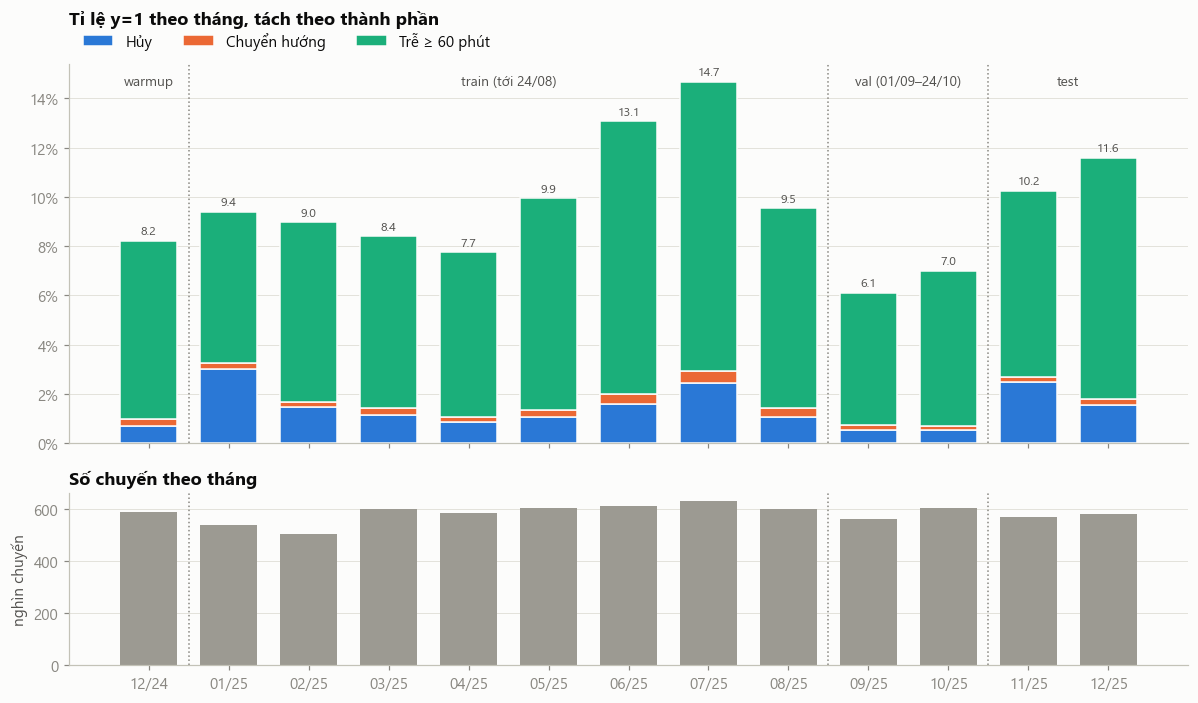

In [3]:
df["_ym"] = df["FlightDate"].dt.to_period("M")
t_month = rate_table(df, "_ym")
labels = [p.strftime("%m/%y") for p in t_month.index]
display(fmt_rates(t_month))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
stacked_rates(ax1, t_month, labels)
ax1.set_title("Tỉ lệ y=1 theo tháng, tách theo thành phần", pad=26)
ax1.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, 1.0))
count_bars(ax2, t_month["n"], labels)
ax2.set_title("Số chuyến theo tháng")
# Ranh giới split (8/25 và 10/25 rơi giữa tháng nên đánh dấu ở biên tháng gần nhất kèm ghi chú)
for ax in (ax1, ax2):
    for x in (0.5, 8.5, 10.5):
        ax.axvline(x, color=MUTED, linestyle=":", linewidth=1)
ymax = ax1.get_ylim()[1]
for x, name in [(0, "warmup"), (4.5, "train (tới 24/08)"), (9.5, "val (01/09–24/10)"), (11.5, "test")]:
    ax1.text(x, ymax * 0.97, name, ha="center", va="top", fontsize=9, color=INK2)
fig.tight_layout(); savefig(fig, "01_rate_by_month"); plt.show()
df.drop(columns="_ym", inplace=True)

## 3. Theo ngày trong tuần (train)

,số chuyến,y=1 %,hủy %,chuyển hướng %,trễ≥60 %
thứ,,,,,
T2,666963,10.99,1.63,0.30,9.06
T3,601522,8.90,1.55,0.32,7.04
T4,626501,9.69,1.65,0.30,7.73
T5,690267,10.95,1.75,0.34,8.86
T6,685472,10.61,1.63,0.28,8.71
T7,597210,8.93,1.21,0.27,7.45
CN,682964,12.23,1.68,0.35,10.20


Đã lưu notebooks\figures\02_rate_by_dow.png


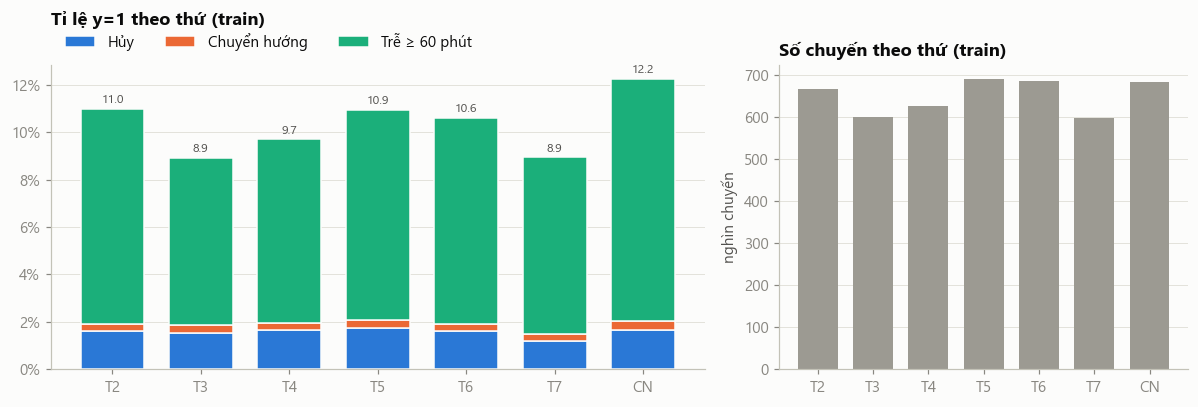

In [4]:
DOW = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]  # BTS DayOfWeek: 1 = thứ Hai ... 7 = Chủ nhật
t_dow = rate_table(train, "DayOfWeek")
display(fmt_rates(t_dow).set_index(pd.Index(DOW, name="thứ")))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
stacked_rates(ax1, t_dow, DOW)
ax1.set_title("Tỉ lệ y=1 theo thứ (train)", pad=26); ax1.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, 1.0))
count_bars(ax2, t_dow["n"], DOW); ax2.set_title("Số chuyến theo thứ (train)")
fig.tight_layout(); savefig(fig, "02_rate_by_dow"); plt.show()

## 4. Theo giờ khởi hành dự kiến (train)
Cột dẫn xuất `dep_hour = CRSDepTime // 100` chỉ dùng để vẽ (giá trị 2400 gộp vào giờ 0).

dep_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
số chuyến,7759,2362,876,476,239,133326,314994,327283,311055,254981,276927,284232,266563,267410,263769,259159,260883,285914,273783,252783,208818,152821,106812,37674
y=1 %,7.15,6.01,7.99,10.5,4.6,5.43,5.15,5.32,5.77,6.01,7.02,7.76,8.99,9.71,11.87,13.05,14.19,15.74,15.77,16.79,15.82,14.42,14.4,8.19
hủy %,1.52,1.06,1.48,0.84,1.26,1.77,1.54,1.22,1.15,1.03,1.13,1.03,1.2,1.12,1.46,1.52,1.81,2.05,2.22,2.37,2.4,2.27,2.96,1.47
chuyển hướng %,0.22,0.13,0.0,0.0,0.0,0.15,0.17,0.22,0.25,0.27,0.3,0.35,0.46,0.47,0.46,0.44,0.39,0.32,0.28,0.27,0.24,0.2,0.18,0.22
trễ≥60 %,5.41,4.83,6.51,9.66,3.35,3.51,3.43,3.89,4.36,4.71,5.59,6.38,7.33,8.13,9.94,11.09,12.0,13.37,13.27,14.15,13.19,11.94,11.26,6.51


Đã lưu notebooks\figures\03_rate_by_dep_hour.png


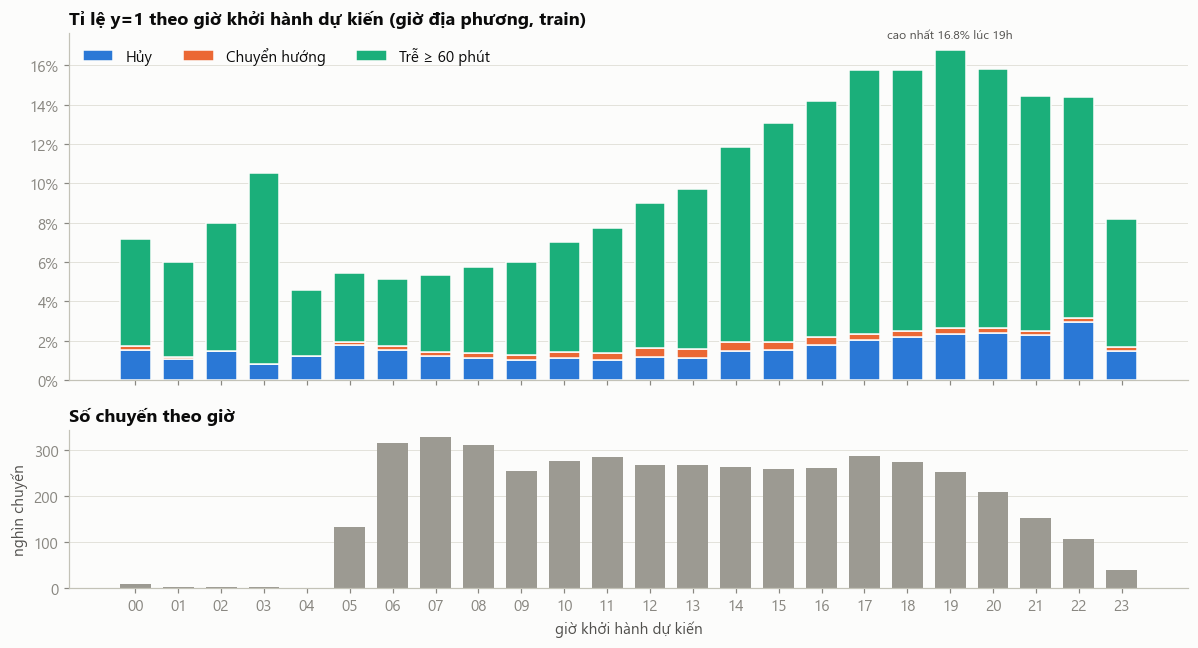

In [5]:
train["dep_hour"] = (train["CRSDepTime"] // 100) % 24
t_hour = rate_table(train, "dep_hour")
display(fmt_rates(t_hour).T)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
hours = [f"{h:02d}" for h in t_hour.index]
stacked_rates(ax1, t_hour, hours, annotate=False)
peak_h = t_hour["y1"].idxmax()
ax1.annotate(f"cao nhất {t_hour.loc[peak_h, 'y1']*100:.1f}% lúc {peak_h:02d}h",
             xy=(list(t_hour.index).index(peak_h), t_hour.loc[peak_h, "y1"] * 100),
             xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax1.set_title("Tỉ lệ y=1 theo giờ khởi hành dự kiến (giờ địa phương, train)")
ax1.legend(loc="upper left", ncol=3)
count_bars(ax2, t_hour["n"], hours); ax2.set_title("Số chuyến theo giờ"); ax2.set_xlabel("giờ khởi hành dự kiến")
fig.tight_layout(); savefig(fig, "03_rate_by_dep_hour"); plt.show()

## 5. Theo hãng bay (train)

,số chuyến,y=1 %,hủy %,chuyển hướng %,trễ≥60 %
Reporting_Airline,,,,,
OH,164442,18.85,5.89,0.29,12.67
F9,128807,14.66,1.98,0.21,12.47
AA,634150,12.94,2.11,0.36,10.48
B6,151886,12.72,1.56,0.44,10.72
YX,221249,11.70,3.54,0.23,7.93
G4,90462,10.94,0.49,0.29,10.17
OO,545474,10.37,1.29,0.36,8.71
NK,137974,9.99,1.39,0.22,8.38
UA,508461,9.91,0.96,0.36,8.59


Đã lưu notebooks\figures\04_rate_by_airline.png


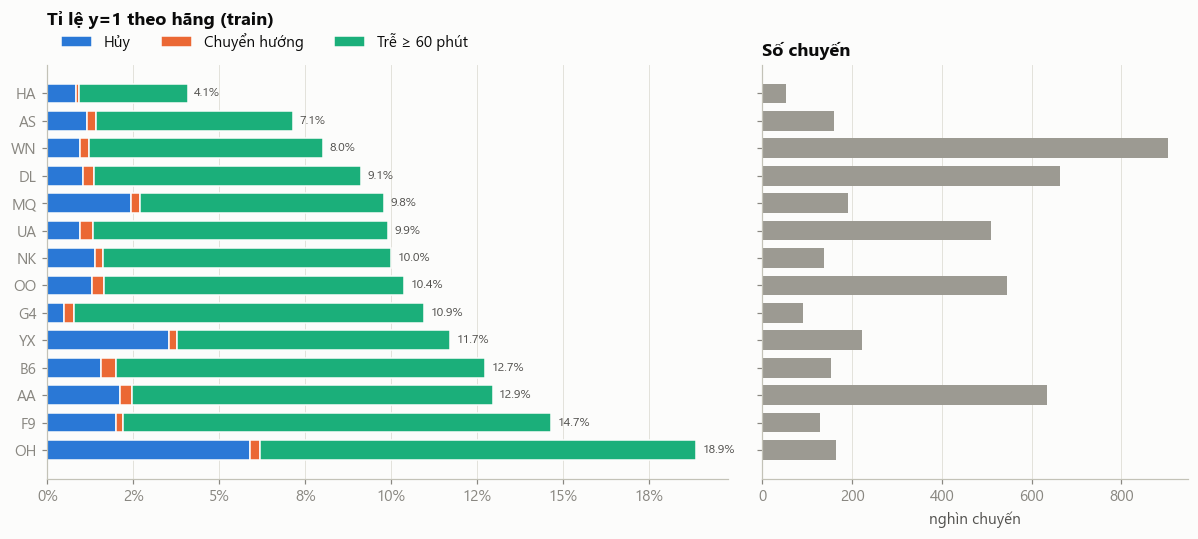

In [6]:
t_air = rate_table(train, "Reporting_Airline").sort_values("y1", ascending=False)
display(fmt_rates(t_air))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
stacked_rates(ax1, t_air, list(t_air.index), horizontal=True)
ax1.set_title("Tỉ lệ y=1 theo hãng (train)", pad=26); ax1.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, 1.0))
count_bars(ax2, t_air["n"], list(t_air.index), horizontal=True); ax2.set_title("Số chuyến")
fig.tight_layout(); savefig(fig, "04_rate_by_airline"); plt.show()

## 6. 20 sân bay đi nhiều chuyến nhất (xếp hạng trên train)

,số chuyến,y=1 %,hủy %,chuyển hướng %,trễ≥60 %
Origin,,,,,
DFW,206227,14.91,3.12,0.34,11.45
DEN,205951,11.62,0.89,0.34,10.39
ORD,203963,11.94,1.54,0.33,10.07
ATL,203723,11.57,1.57,0.30,9.70
CLT,130822,12.29,2.21,0.25,9.83
PHX,128673,6.78,0.58,0.28,5.93
LAX,124067,7.03,0.63,0.35,6.05
LAS,121587,7.47,0.74,0.33,6.39
SEA,107411,6.75,0.73,0.29,5.72


Đã lưu notebooks\figures\05_rate_top20_origin.png


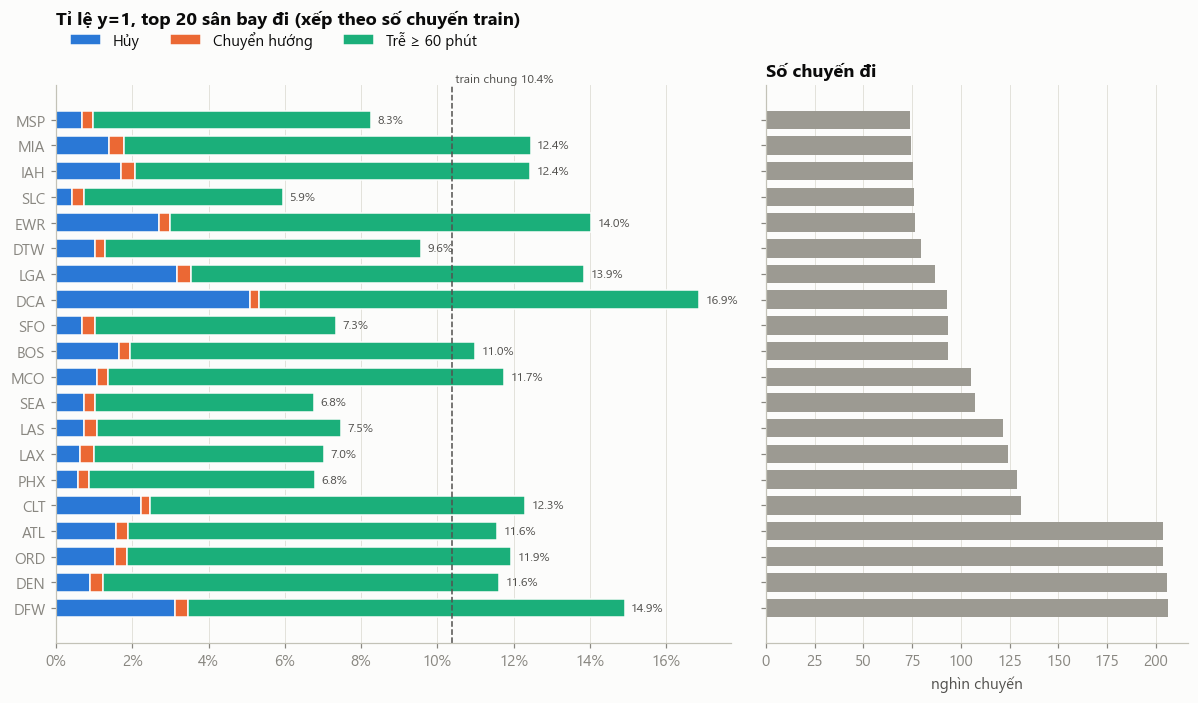

In [7]:
origin_counts = train["Origin"].value_counts()
origin_counts = origin_counts[origin_counts > 0]
top20 = origin_counts.head(20).index
t_ap = rate_table(train[train["Origin"].isin(top20)], "Origin").loc[top20]
display(fmt_rates(t_ap))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
stacked_rates(ax1, t_ap, list(t_ap.index.astype(str)), horizontal=True)
overall = train["y"].mean() * 100
ax1.axvline(overall, color=INK2, linestyle="--", linewidth=1)
ax1.text(overall, 1.0, f" train chung {overall:.1f}%", fontsize=8, color=INK2, ha="left", va="bottom",
         transform=ax1.get_xaxis_transform())
ax1.set_title("Tỉ lệ y=1, top 20 sân bay đi (xếp theo số chuyến train)", pad=40)
ax1.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, 1.04))
count_bars(ax2, t_ap["n"], list(t_ap.index.astype(str)), horizontal=True); ax2.set_title("Số chuyến đi")
fig.tight_layout(); savefig(fig, "05_rate_top20_origin"); plt.show()

## 7. Mức tập trung sân bay (train)

Train: 4,550,899 chuyến | sân bay đi: 349 | sân bay đến: 349 | tổng khác nhau: 349


,% chuyến có Origin trong top N,% chuyến có cả Origin và Dest trong top N,tỉ lệ y=1 (Origin trong top N) %,tỉ lệ y=1 (ngoài top N) %
top N (theo số chuyến đi),,,,
20,51.85,21.24,10.90,9.83
50,78.38,58.59,10.40,10.32
100,91.35,83.31,10.27,11.56


Đã lưu notebooks\figures\06_airport_concentration.png


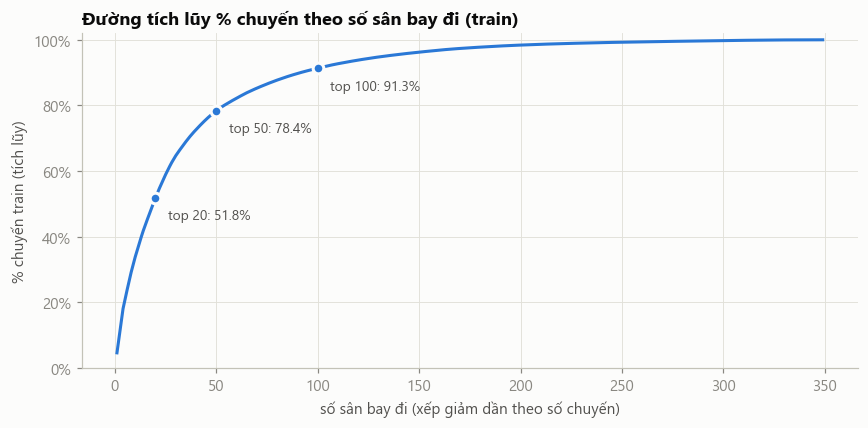

In [8]:
n_origin = int((train["Origin"].value_counts() > 0).sum())
n_dest = int((train["Dest"].value_counts() > 0).sum())
n_any = len(set(train["Origin"].astype(str)) | set(train["Dest"].astype(str)))
print(f"Train: {len(train):,} chuyến | sân bay đi: {n_origin} | sân bay đến: {n_dest} | tổng khác nhau: {n_any}")

rows = []
for n in cfg["eda"]["top_n_airports"]:
    top = set(origin_counts.head(n).index)
    in_o = train["Origin"].isin(top)
    in_both = in_o & train["Dest"].isin(top)
    rows.append({"top N (theo số chuyến đi)": n,
                 "% chuyến có Origin trong top N": round(in_o.mean() * 100, 2),
                 "% chuyến có cả Origin và Dest trong top N": round(in_both.mean() * 100, 2),
                 "tỉ lệ y=1 (Origin trong top N) %": round(train.loc[in_o, "y"].mean() * 100, 2),
                 "tỉ lệ y=1 (ngoài top N) %": round(train.loc[~in_o, "y"].mean() * 100, 2)})
conc = pd.DataFrame(rows).set_index("top N (theo số chuyến đi)")
display(conc)

cum = origin_counts.cumsum() / origin_counts.sum() * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cum) + 1), cum.to_numpy(), color="#2a78d6", linewidth=2)
for n in cfg["eda"]["top_n_airports"]:
    ax.plot(n, cum.iloc[n - 1], "o", color="#2a78d6", markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"top {n}: {cum.iloc[n-1]:.1f}%", (n, cum.iloc[n - 1]), xytext=(8, -14),
                textcoords="offset points", fontsize=9, color=INK2)
ax.set_xlabel("số sân bay đi (xếp giảm dần theo số chuyến)"); ax.set_ylabel("% chuyến train (tích lũy)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, 102)
ax.set_title("Đường tích lũy % chuyến theo số sân bay đi (train)")
fig.tight_layout(); savefig(fig, "06_airport_concentration"); plt.show()

## 8. Phân phối `ArrDelay` (train)

Số giá trị: 4,464,396 | min=-128 | max=3407 | mean=9.49
% ArrDelay < 0 (đến sớm): 59.91% | % >= 15: 23.07% | % >= 60: 8.65% | % >= 180: 1.73%


,0.010,0.050,0.250,0.500,0.750,0.900,0.950,0.990,0.999
ArrDelay (phút),-37.0,-27.0,-15.0,-5.0,12.0,51.0,95.0,232.0,781.0


Đã lưu notebooks\figures\07_arrdelay_distribution.png


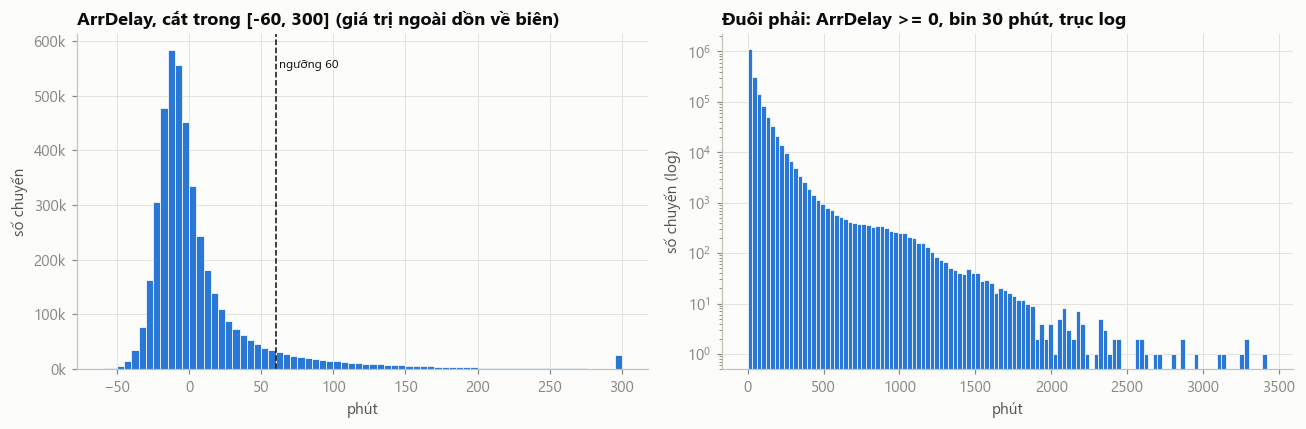

In [9]:
arr = train["ArrDelay"].dropna().astype(float)
q = arr.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
print(f"Số giá trị: {len(arr):,} | min={arr.min():.0f} | max={arr.max():.0f} | mean={arr.mean():.2f}")
print(f"% ArrDelay < 0 (đến sớm): {(arr < 0).mean()*100:.2f}% | % >= 15: {(arr >= 15).mean()*100:.2f}% | "
      f"% >= 60: {(arr >= 60).mean()*100:.2f}% | % >= 180: {(arr >= 180).mean()*100:.2f}%")
display(q.rename("ArrDelay (phút)").to_frame().T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(-60, 301, 5)
ax1.hist(arr.clip(-60, 300), bins=bins, color="#2a78d6", edgecolor=SURFACE, linewidth=0.5)
ax1.axvline(60, color=INK, linestyle="--", linewidth=1); ax1.text(62, ax1.get_ylim()[1] * 0.9, "ngưỡng 60", fontsize=8)
ax1.set_title("ArrDelay, cắt trong [-60, 300] (giá trị ngoài dồn về biên)")
ax1.set_xlabel("phút"); ax1.set_ylabel("số chuyến")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
bins2 = np.arange(0, arr.max() + 31, 30)
ax2.hist(arr[arr >= 0], bins=bins2, color="#2a78d6", edgecolor=SURFACE, linewidth=0.5)
ax2.set_yscale("log"); ax2.set_title("Đuôi phải: ArrDelay >= 0, bin 30 phút, trục log")
ax2.set_xlabel("phút"); ax2.set_ylabel("số chuyến (log)")
fig.tight_layout(); savefig(fig, "07_arrdelay_distribution"); plt.show()

## 9. Giá trị thiếu theo cột

,thiếu (toàn bộ),% toàn bộ,warmup,train,gap,val,test
FlightDate,0,0.000,0,0,0,0,0
Reporting_Airline,0,0.000,0,0,0,0,0
Flight_Number_Reporting_Airline,0,0.000,0,0,0,0,0
Origin,0,0.000,0,0,0,0,0
Dest,0,0.000,0,0,0,0,0
CRSDepTime,0,0.000,0,0,0,0,0
CRSArrTime,0,0.000,0,0,0,0,0
CRSElapsedTime,2,0.000,0,2,0,0,0
Distance,0,0.000,0,0,0,0,0
Cancelled,0,0.000,0,0,0,0,0


Đã lưu notebooks\figures\08_missing_values.png


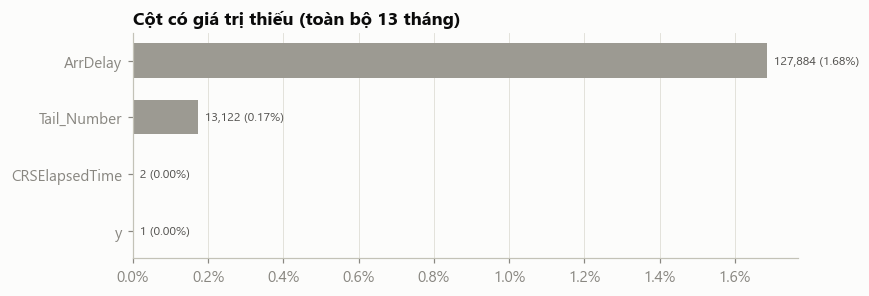

Thiếu ArrDelay theo trạng thái:


hủy               False          True 
chuyển hướng      False  True    False
ArrDelay thiếu                        
False           7464316      0       0
True                  1  20856  107027

In [10]:
miss_all = df.isna().sum().rename("thiếu (toàn bộ)")
miss_split = df.isna().groupby(df["split"], observed=True).sum().T
miss = pd.concat([miss_all, (miss_all / len(df) * 100).round(3).rename("% toàn bộ"), miss_split], axis=1)
display(miss)

has_miss = miss_all[miss_all > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(has_miss.index, has_miss / len(df) * 100, color=COUNT_COLOR, height=0.6)
for i, v in enumerate(has_miss):
    ax.text(v / len(df) * 100, i, f"  {v:,} ({v/len(df)*100:.2f}%)", va="center", fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=1)); ax.grid(axis="y", visible=False)
ax.set_title("Cột có giá trị thiếu (toàn bộ 13 tháng)")
fig.tight_layout(); savefig(fig, "08_missing_values"); plt.show()

print("Thiếu ArrDelay theo trạng thái:")
display(pd.crosstab(df["ArrDelay"].isna(), [df["is_cancelled"], df["is_diverted"]],
                    rownames=["ArrDelay thiếu"], colnames=["hủy", "chuyển hướng"]))

## 10. Số chuyến theo ngày (toàn bộ 13 tháng)
Ngày "bất thường" = số chuyến lệch quá 10% so với **trung vị cùng thứ** trong ±3 tuần lân cận (6 ngày cùng thứ). Chỉ dùng số chuyến, không dùng nhãn.

Ngày không có chuyến nào: []
Số ngày lệch > 10%: 23


,n,expected,ratio,thứ,split
2024-12-07,16209,19463.0,0.833,T7,warmup
2024-12-14,16250,19003.5,0.855,T7,warmup
2024-12-21,19492,16250.0,1.200,T7,warmup
2024-12-28,19463,16229.5,1.199,T7,warmup
2025-01-04,18544,15638.0,1.186,T7,train
2025-01-11,14991,16797.5,0.892,T7,train
2025-07-04,16621,21468.5,0.774,T6,train
2025-08-31,17714,20462.5,0.866,CN,gap
2025-10-31,17091,20768.5,0.823,T6,gap
2025-11-22,18828,16524.5,1.139,T7,test


Đã lưu notebooks\figures\09_flights_per_day.png


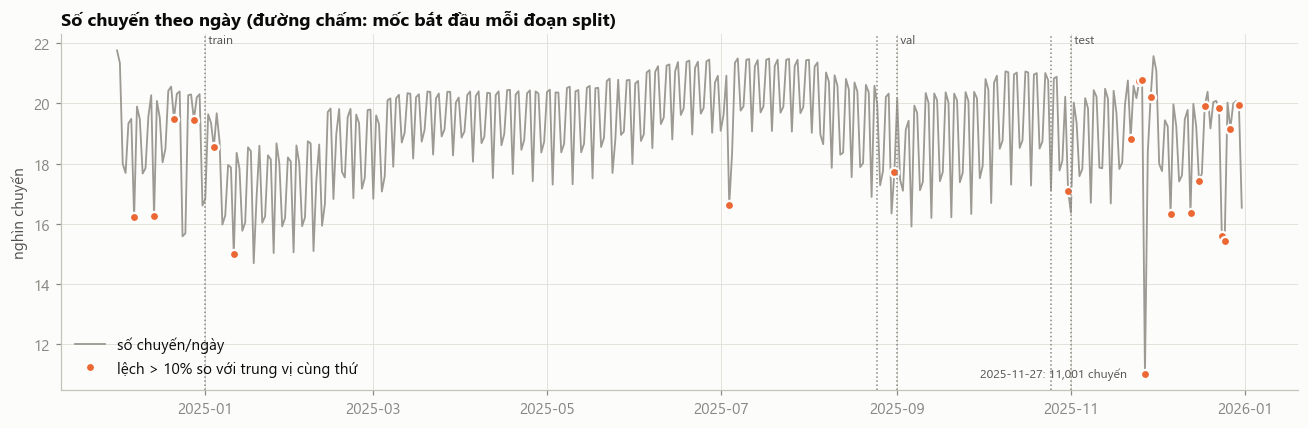

In [11]:
daily = df.groupby("FlightDate").size().rename("n").to_frame()
full_idx = pd.date_range(df["FlightDate"].min(), df["FlightDate"].max(), freq="D")
print("Ngày không có chuyến nào:", list(full_idx.difference(daily.index).date))
daily = daily.reindex(full_idx, fill_value=0)
neigh = pd.concat([daily["n"].shift(k) for k in (-21, -14, -7, 7, 14, 21)], axis=1)
daily["expected"] = neigh.median(axis=1)
daily["ratio"] = daily["n"] / daily["expected"]
anom = daily[(daily["ratio"] - 1).abs() > 0.10].copy()
anom["thứ"] = [["T2","T3","T4","T5","T6","T7","CN"][d.dayofweek] for d in anom.index]
anom["split"] = df.drop_duplicates("FlightDate").set_index("FlightDate").loc[anom.index, "split"].astype(str).values
print(f"Số ngày lệch > 10%: {len(anom)}")
display(anom.assign(ratio=anom["ratio"].round(3)))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily["n"] / 1e3, color=COUNT_COLOR, linewidth=1.2, label="số chuyến/ngày")
ax.plot(anom.index, anom["n"] / 1e3, "o", color="#eb6834", markersize=6, markeredgecolor=SURFACE,
        markeredgewidth=1.5, label="lệch > 10% so với trung vị cùng thứ")
for rng in cfg["split"]["ranges"][1:]:
    ax.axvline(pd.Timestamp(rng["start"]), color=MUTED, linestyle=":", linewidth=1)
    if rng["name"] != "gap":  # gap chỉ vẽ đường, không ghi chữ để khỏi chồng nhãn
        ax.text(pd.Timestamp(rng["start"]), ax.get_ylim()[1], f" {rng['name']}", fontsize=8, color=INK2, va="top")
dmin = daily["n"].idxmin()
ax.annotate(f"{dmin.date()}: {daily.loc[dmin, 'n']:,} chuyến", (dmin, daily.loc[dmin, "n"] / 1e3),
            xytext=(-12, 0), textcoords="offset points", ha="right", va="center", fontsize=8, color=INK2)
ax.set_ylabel("nghìn chuyến"); ax.set_title("Số chuyến theo ngày (đường chấm: mốc bắt đầu mỗi đoạn split)")
ax.legend(loc="lower left")
fig.tight_layout(); savefig(fig, "09_flights_per_day"); plt.show()

## 11. Ngày có tỉ lệ y=1 cao nhất (train)

In [12]:
t_day = rate_table(train, "FlightDate").sort_values("y1", ascending=False)
display(fmt_rates(t_day.head(10)))
print(f"Trung vị tỉ lệ y=1 theo ngày (train): {t_day['y1'].median()*100:.2f}% | "
      f"số ngày y=1 > 20%: {(t_day['y1'] > 0.2).sum()} / {len(t_day)}")
print(f"RAM đỉnh kernel: {peak_rss_mb():.0f} MB")

,số chuyến,y=1 %,hủy %,chuyển hướng %,trễ≥60 %
FlightDate,,,,,
2025-02-16,18978,28.24,6.52,0.67,21.05
2025-01-10,17873,27.04,15.98,0.19,10.87
2025-03-16,20206,26.76,4.31,0.45,22.01
2025-01-06,18732,26.36,9.96,0.27,16.13
2025-03-31,20198,25.33,5.28,0.93,19.12
2025-07-13,21237,25.27,5.36,0.68,19.24
2025-07-31,21436,24.82,7.17,0.89,16.76
2025-07-14,21445,24.50,7.75,0.65,16.09
2025-06-27,21460,22.81,5.32,0.61,16.89


Trung vị tỉ lệ y=1 theo ngày (train): 9.01% | số ngày y=1 > 20%: 16 / 236
RAM đỉnh kernel: 1985 MB


## 12. Nhận xét (chỉ nêu điều thấy trong số liệu của lần chạy này)

**Chất lượng dữ liệu**
- 7.592.200 chuyến, đủ 13 tháng, không có dòng trùng (toàn phần và theo khóa chuyến bay). Không có ngày nào thiếu dữ liệu.
- Chỉ **1 dòng "chưa xác định"**: 2025-09-06, YX 5859 JFK→MVY (thuộc val), không hủy, không chuyển hướng nhưng thiếu `ArrDelay`. Đây cũng là lý do duy nhất khiến tháng 9/2025 lệch 1 giữa "`ArrDelay` thiếu" và "hủy + chuyển hướng"; 12 tháng còn lại khớp đúng.
- Thiếu khác: `Tail_Number` 13.122 dòng (0,17%), `CRSElapsedTime` 2 dòng (train). Giá trị `2400`: 1 dòng `CRSDepTime` (7/2025), 2 dòng `CRSArrTime` (8/2025); không có giá trị hhmm sai định dạng.

**Tỉ lệ y=1 và thành phần**
- Toàn bộ: y=1 = 9,66% (trễ ≥ 60: 7,97%, hủy: 1,41%, chuyển hướng: 0,27%). Trễ ≥ 60 là thành phần lớn nhất ở mọi tháng.
- Theo split: warmup 8,21%, **train 10,39%**, **val 6,15%**, **test 10,93%**. Val (9–10/2025) là giai đoạn có tỉ lệ thấp nhất trong 13 tháng (9/2025: 6,11%; 10/2025: 6,99%), thấp hơn rõ so với train và test.
- Theo tháng: cao nhất 7/2025 (14,68%) và 6/2025 (13,07%); hủy cao nhất ở 1/2025 (3,02%) và 11/2025 (2,49%).
- Theo thứ (train): Chủ nhật cao nhất (12,23%), thứ Ba (8,90%) và thứ Bảy (8,93%) thấp nhất.
- Theo giờ khởi hành dự kiến (train): tăng dần trong ngày, từ khoảng 5,2–5,8% (05–08h) lên cao nhất 16,79% lúc 19h. Khung 00–04h có rất ít chuyến (04h chỉ 239 chuyến) nên tỉ lệ ở đó dao động mạnh.
- Theo hãng (train, 14 hãng): OH cao nhất (18,85%, riêng hủy 5,89%), tiếp theo F9 (14,66%), AA (12,94%); HA thấp nhất (4,09%).
- Top 20 sân bay đi (train): DCA cao nhất (16,87%, hủy 5,07%), DFW 14,91%, EWR 14,03%, LGA 13,86%; thấp nhất SLC 5,94%, SEA 6,75%, PHX 6,78%.

**Mức tập trung sân bay (train)**
- 349 sân bay đi. Top 20 / 50 / 100 sân bay đi chiếm **51,85% / 78,38% / 91,35%** chuyến; tỉ lệ chuyến có **cả** sân bay đi và đến trong top N là 21,24% / 58,59% / 83,31%.
- y=1 của chuyến có Origin trong top 100 là 10,27%, của chuyến ngoài top 100 là 11,56%.

**`ArrDelay` (train, 4.464.396 giá trị)**
- Trung vị −5 phút, 59,91% đến sớm; p90 = 51, p95 = 95, p99 = 232, max = 3.407 phút. 8,65% có `ArrDelay` ≥ 60.

**Số chuyến theo ngày**
- Thấp nhất 2025-11-27 (11.001 chuyến, bằng 0,55 trung vị cùng thứ; ngày Lễ Tạ ơn), tiếp theo 2025-07-04 (0,77) và 2025-12-25 (0,79). Có 23 ngày lệch quá 10%, tập trung ở 12/2024, cuối 11/2025 và 12/2025; một phần các ngày thứ Bảy bị đánh dấu là do trung vị tham chiếu (±3 tuần) chứa các tuần lễ hội.
- Ngày train có y=1 cao nhất: 2025-02-16 (28,24%), 2025-01-10 (27,04%, riêng hủy 15,98%); 16/236 ngày train có y=1 > 20% (trung vị theo ngày 9,01%).